## LOAD PARAMETER

In [1]:
import json 
import os
import numpy as np 

path = "./params"

files = os.listdir(path=path)

print(files)

json_file = None

with open(os.path.join(path, "model_results.json"), 'r', encoding='utf-8') as f:
    json_file = json.load(f)

['softmax-10-bias.npz', 'neural-9-weights.npz', 'conv2d-1-bias.npz', 'pool-2-bias.npz', 'conv2d-3-weights.npz', 'conv2d-3-bias.npz', 'model_results.json', 'pool-6-bias.npz', '.gitignore', 'conv2d-5-weights.npz', 'neural-8-bias.npz', 'pool-6-weights.npz', 'pool-2-weights.npz', 'pool-4-bias.npz', 'conv2d-1-weights.npz', 'pool-4-weights.npz', 'flatten-7-weights.npz', 'neural-8-weights.npz', 'neural-9-bias.npz', 'softmax-10-weights.npz', 'conv2d-5-bias.npz', 'flatten-7-bias.npz']


In [2]:
layer_map = ['neural', 'conv2d', 'pool', 'flatten']

model_conf = json_file['configuration']
print(f"layer length : {len(model_conf)} layers")

layer length : 10 layers


In [3]:
import os
import numpy as np

def load_npz_array(file_path: str, key: str, dtype=np.float32):
    data = np.load(file_path, allow_pickle=True)
    arr = data[key]

    if isinstance(arr, np.ndarray) and arr.dtype == object:
        if arr.shape == ():
            arr = arr.item()
        else:
            arr = np.array(arr.tolist())

    arr = np.asarray(arr, dtype=dtype)

    return arr


weights_bias = {}

for i in model_conf:
    has_forward = i["forward"]
    model_name = i["name"]

    if has_forward:
        weights_path = os.path.join(path, i["wparam"])
        bias_path = os.path.join(path, i["bparam"])

        w_matrix = load_npz_array(weights_path, "weights")
        b_matrix = load_npz_array(bias_path, "bias")

        print(
            w_matrix.shape,
            w_matrix.dtype,
            b_matrix.shape,
            b_matrix.dtype,
            model_name
        )

        weights_bias[model_name] = {
            "w": w_matrix,
            "b": b_matrix
        }

    else:
        weights_bias[model_name] = None

(8, 1, 3, 3) float32 (8,) float32 conv2d-1
(1,) float32 (1,) float32 pool-2
(16, 8, 3, 3) float32 (16,) float32 conv2d-3
(1,) float32 (1,) float32 pool-4
(32, 16, 3, 3) float32 (32,) float32 conv2d-5
(1,) float32 (1,) float32 pool-6
(1,) float32 (1,) float32 flatten-7
(32, 16) float32 (1, 16) float32 neural-8
(16, 10) float32 (1, 10) float32 neural-9
(1,) float32 (1,) float32 softmax-10


In [4]:
conv1_weights = weights_bias['conv2d-1']['w']
conv1_bias = weights_bias['conv2d-1']['b']

In [5]:
conv2_weights = weights_bias['conv2d-3']['w']
conv2_bias = weights_bias['conv2d-3']['b']

In [6]:
conv3_weights = weights_bias['conv2d-5']['w']
conv3_bias = weights_bias['conv2d-5']['b']

In [7]:
neural1_weights = weights_bias["neural-8"]["w"]
neural1_bias = weights_bias["neural-8"]["b"]

In [8]:
neural2_weights = weights_bias["neural-9"]["w"]
neural2_bias = weights_bias["neural-9"]["b"]

## QUANTITIZE PARAMETER SIGNED Q2.14

In [9]:
import numpy as np

In [10]:
def quantize_signed(value, total_bits, fractional_bits):
    scale = 1 << fractional_bits

    q = np.round(value * scale).astype(np.int64)

    min_q = -(1 << (total_bits - 1))
    max_q =  (1 << (total_bits - 1)) - 1

    sat_low = np.sum(q < min_q)
    sat_high = np.sum(q > max_q)

    fixed_point = np.clip(q, min_q, max_q)

    return fixed_point, sat_low, sat_high

def int_to_hex_twos_complement(v, bits):
    if v < 0:
        v = (1 << bits) + v

    hex_digits = bits // 4
    return f"{v:0{hex_digits}X}"

def save_mem(filename, q, bits, word_16_bit=1):
    q_flat = q.flatten()

    if bits != 16:
        raise ValueError("Fungsi ini mengasumsikan setiap parameter = 16 bit")

    if word_16_bit <= 0:
        raise ValueError("word_16_bit harus >= 1")

    word_size = word_16_bit
    total = len(q_flat)

    with open(filename, "w") as f:

        for start in range(0, total, word_size):

            # Ambil parameter untuk 1 word
            chunk = q_flat[start:start + word_size]

            # Balik supaya parameter pertama menjadi LSB
            for value in reversed(chunk):
                f.write(
                    int_to_hex_twos_complement(
                        int(value),
                        bits
                    )
                )

            f.write("\n")

    print(f"saved: {filename}")
    print("total parameters :", total)
    print("word_16_bit      :", word_16_bit)
    print("word width       :", word_16_bit * 16, "bit")
    print("number of words  :", (total + word_size - 1) // word_size)

In [11]:
OUT_DIR = "rom_mem"
os.makedirs(OUT_DIR, exist_ok=True)

FRAC_BITS = 14
W_BITS = 16
B_BITS = 16

### CONV1

In [12]:
w1 = conv1_weights
b1 = conv1_bias

print("w1 shape:", w1.shape)
print("b1 shape:", b1.shape)

assert w1.shape == (8, 1, 3, 3), f"w1 shape salah: {w1.shape}"
assert b1.shape == (8,), f"b1 shape salah: {b1.shape}"

w1_hw = w1
b1_hw = b1

print(f"range conv1 w: {np.max(w1_hw)}, {np.min(w1_hw)}")
print(f"range conv1 b: {np.max(b1_hw)}, {np.min(b1_hw)}")

q_w1, sat_w1_low, sat_w1_high = quantize_signed(w1_hw, W_BITS, FRAC_BITS)
q_b1, sat_b1_low, sat_b1_high = quantize_signed(b1_hw, B_BITS, FRAC_BITS)

print("="*50)

print("Weight saturation low :", sat_w1_low)
print("Weight saturation high:", sat_w1_high)
print("Bias saturation low   :", sat_b1_low)
print("Bias saturation high  :", sat_b1_high)

print("="*50)

print("q_w1 min/max:", q_w1.min(), q_w1.max())
print("q_b1 min/max:", q_b1.min(), q_b1.max())

print("="*50)

save_mem(f"{OUT_DIR}/conv1_w.mem", q_w1, W_BITS, word_16_bit=72)
save_mem(f"{OUT_DIR}/conv1_b.mem", q_b1, B_BITS, word_16_bit=8)

w1 shape: (8, 1, 3, 3)
b1 shape: (8,)
range conv1 w: 0.22917887568473816, -0.416494756937027
range conv1 b: 0.2018362581729889, -0.1290275901556015
Weight saturation low : 0
Weight saturation high: 0
Bias saturation low   : 0
Bias saturation high  : 0
q_w1 min/max: -6824 3755
q_b1 min/max: -2114 3307
saved: rom_mem/conv1_w.mem
total parameters : 72
word_16_bit      : 72
word width       : 1152 bit
number of words  : 1
saved: rom_mem/conv1_b.mem
total parameters : 8
word_16_bit      : 8
word width       : 128 bit
number of words  : 1


### CONV2

In [13]:
w2 = conv2_weights
b2 = conv2_bias

print("w2 shape:", w2.shape)
print("b2 shape:", b2.shape)

assert w2.shape == (16, 8, 3, 3), f"w2 shape salah: {w2.shape}"
assert b2.shape == (16,), f"b2 shape salah: {b2.shape}"

print(f"range conv2 w: {np.max(conv2_weights)}, {np.min(conv2_weights)}")
print(f"range conv2 b: {np.max(conv2_bias)}, {np.min(conv2_bias)}")

q_w2, sat_w2_low, sat_w2_high = quantize_signed(w2, W_BITS, FRAC_BITS)
q_b2, sat_b2_low, sat_b2_high = quantize_signed(b2, B_BITS, FRAC_BITS)

print("="*50)

print("Weight saturation low :", sat_w2_low)
print("Weight saturation high:", sat_w2_high)
print("Bias saturation low   :", sat_b2_low)
print("Bias saturation high  :", sat_b2_high)

print("="*50)

print("q_w2 min/max:", q_w2.min(), q_w2.max())
print("q_b2 min/max:", q_b2.min(), q_b2.max())

print("="*50)

save_mem(f"{OUT_DIR}/conv2_w.mem", q_w2, W_BITS, word_16_bit=72)
save_mem(f"{OUT_DIR}/conv2_b.mem", q_b2, B_BITS, word_16_bit=8)

w2 shape: (16, 8, 3, 3)
b2 shape: (16,)
range conv2 w: 0.2740287184715271, -0.4300774037837982
range conv2 b: 0.16609081625938416, -0.14580757915973663
Weight saturation low : 0
Weight saturation high: 0
Bias saturation low   : 0
Bias saturation high  : 0
q_w2 min/max: -7046 4490
q_b2 min/max: -2389 2721
saved: rom_mem/conv2_w.mem
total parameters : 1152
word_16_bit      : 72
word width       : 1152 bit
number of words  : 16
saved: rom_mem/conv2_b.mem
total parameters : 16
word_16_bit      : 8
word width       : 128 bit
number of words  : 2


### CONV3

In [14]:
w3 = conv3_weights
b3 = conv3_bias

print("w3 shape:", w3.shape)
print("b3 shape:", b3.shape)

assert w3.shape == (32, 16, 3, 3), f"w2 shape salah: {w3.shape}"
assert b3.shape == (32,), f"b2 shape salah: {b3.shape}"

print(f"range conv3 w: {np.max(conv3_weights)}, {np.min(conv3_weights)}")
print(f"range conv3 b: {np.max(conv3_bias)}, {np.min(conv3_bias)}")

q_w3, sat_w3_low, sat_w3_high = quantize_signed(w3, W_BITS, FRAC_BITS)
q_b3, sat_b3_low, sat_b3_high = quantize_signed(b3, B_BITS, FRAC_BITS)

print("="*50)

print("Weight saturation low :", sat_w3_low)
print("Weight saturation high:", sat_w3_high)
print("Bias saturation low   :", sat_b3_low)
print("Bias saturation high  :", sat_b3_high)

print("="*50)

print("q_w3 min/max:", q_w3.min(), q_w3.max())
print("q_b3 min/max:", q_b3.min(), q_b3.max())

print("="*50)

save_mem(f"{OUT_DIR}/conv3_w.mem", q_w3, W_BITS, word_16_bit=72)
save_mem(f"{OUT_DIR}/conv3_b.mem", q_b3, B_BITS, word_16_bit=8)

w3 shape: (32, 16, 3, 3)
b3 shape: (32,)
range conv3 w: 0.29361698031425476, -0.2786199152469635
range conv3 b: 0.10558171570301056, -0.11602800339460373
Weight saturation low : 0
Weight saturation high: 0
Bias saturation low   : 0
Bias saturation high  : 0
q_w3 min/max: -4565 4811
q_b3 min/max: -1901 1730
saved: rom_mem/conv3_w.mem
total parameters : 4608
word_16_bit      : 72
word width       : 1152 bit
number of words  : 64
saved: rom_mem/conv3_b.mem
total parameters : 32
word_16_bit      : 8
word width       : 128 bit
number of words  : 4


### FC1

In [15]:
wfc1 = neural1_weights
bfc1 = neural1_bias

print("fc1_w shape:", wfc1.shape)
print("fc1_b shape:", bfc1.shape)

assert wfc1.shape == (32, 16), f"w fc1 shape salah: {wfc1.shape}"
assert bfc1.shape == (1, 16), f"b fc1 shape salah: {bfc1.shape}"

wfc1_hw = wfc1.T
bfc1_hw = bfc1.reshape(-1)

print(f"range fc1 w: {np.max(wfc1_hw)}, {np.min(wfc1_hw)}")
print(f"range fc1 b: {np.max(bfc1_hw)}, {np.min(bfc1_hw)}")

q_wfc1_hw, sat_w_fc1_low, sat_w_fc1_high = quantize_signed(wfc1_hw, W_BITS, FRAC_BITS)
q_bfc1_hw, sat_b_fc1_low, sat_b_fc1_high = quantize_signed(bfc1_hw, B_BITS, FRAC_BITS)

print("="*50)

print("Weight saturation low :", sat_w_fc1_low)
print("Weight saturation high:", sat_w_fc1_high)
print("Bias saturation low   :", sat_b_fc1_low)
print("Bias saturation high  :", sat_b_fc1_high)

print("="*50)

print("q_fc1_w min/max:", q_wfc1_hw.min(), q_wfc1_hw.max())
print("q_fc1_b min/max:", q_bfc1_hw.min(), q_bfc1_hw.max())

print("="*50)

save_mem(f"{OUT_DIR}/fc1_w.mem", q_wfc1_hw, W_BITS, word_16_bit=8)
save_mem(f"{OUT_DIR}/fc1_b.mem", q_bfc1_hw, B_BITS, word_16_bit=8)

fc1_w shape: (32, 16)
fc1_b shape: (1, 16)
range fc1 w: 0.5645610690116882, -0.5869250893592834
range fc1 b: 0.013844355940818787, -0.009936407208442688
Weight saturation low : 0
Weight saturation high: 0
Bias saturation low   : 0
Bias saturation high  : 0
q_fc1_w min/max: -9616 9250
q_fc1_b min/max: -163 227
saved: rom_mem/fc1_w.mem
total parameters : 512
word_16_bit      : 8
word width       : 128 bit
number of words  : 64
saved: rom_mem/fc1_b.mem
total parameters : 16
word_16_bit      : 8
word width       : 128 bit
number of words  : 2


### FC2

In [33]:
neural2_weights.shape

(16, 10)

In [16]:
wfc2 = neural2_weights
bfc2 = neural2_bias

print("fc2_w shape:", wfc2.shape)
print("fc2_b shape:", bfc2.shape)

assert wfc2.shape == (16, 10), f"w fc2 shape salah: {wfc2.shape}"
assert bfc2.shape == (1, 10), f"b fc2 shape salah: {bfc2.shape}"

wfc2_hw = wfc2.T
bfc2_hw = bfc2.reshape(-1)

print(f"range fc2 w: {np.max(wfc2_hw)}, {np.min(wfc2_hw)}")
print(f"range fc2 b: {np.max(bfc2_hw)}, {np.min(bfc2_hw)}")

q_wfc2_hw, sat_w_fc2_low, sat_w_fc2_high = quantize_signed(wfc2_hw, W_BITS, FRAC_BITS)
q_bfc2_hw, sat_b_fc2_low, sat_b_fc2_high = quantize_signed(bfc2_hw, B_BITS, FRAC_BITS)

print("="*50)

print("Weight saturation low :", sat_w_fc2_low)
print("Weight saturation high:", sat_w_fc2_high)
print("Bias saturation low   :", sat_b_fc2_low)
print("Bias saturation high  :", sat_b_fc2_high)

print("="*50)

print("q_fc2_w min/max:", q_wfc2_hw.min(), q_wfc2_hw.max())
print("q_fc2_b min/max:", q_bfc2_hw.min(), q_bfc2_hw.max())

print("="*50)

save_mem(f"{OUT_DIR}/fc2_w.mem", q_wfc2_hw, W_BITS, word_16_bit=8)
save_mem(f"{OUT_DIR}/fc2_b.mem", q_bfc2_hw, B_BITS, word_16_bit=10)

fc2_w shape: (16, 10)
fc2_b shape: (1, 10)
range fc2 w: 0.8179162740707397, -0.5849517583847046
range fc2 b: 0.13607853651046753, -0.07051874697208405
Weight saturation low : 0
Weight saturation high: 0
Bias saturation low   : 0
Bias saturation high  : 0
q_fc2_w min/max: -9584 13401
q_fc2_b min/max: -1155 2230
saved: rom_mem/fc2_w.mem
total parameters : 160
word_16_bit      : 8
word width       : 128 bit
number of words  : 20
saved: rom_mem/fc2_b.mem
total parameters : 10
word_16_bit      : 10
word width       : 160 bit
number of words  : 1


## SATURATION PARAMETER CHECK

### PARAMETER SATURATION GRAPH (Q2.14)

In [17]:
MIN_FLOAT_Q2_14 = -2.0
MAX_FLOAT_Q2_14 = 1.99993896484375
Q_FLOAT_SATURATION = 0.00006103515625

MIN_BIT_Q2_14 = -32768
MAX_BIT_Q2_14 = 32767

In [18]:
def analyze_quantization_bit(name, quant_data):
    quant_data = np.asarray(quant_data)

    qmin = quant_data.min()
    qmax = quant_data.max()

    bit_dist_min = qmin - MIN_BIT_Q2_14
    bit_dist_max = MAX_BIT_Q2_14 - qmax
    bit_range = MAX_BIT_Q2_14 - MIN_BIT_Q2_14
    bit_used = (qmax - qmin) / bit_range * 100
    bit_margin = min(bit_dist_min, bit_dist_max)
    
    print("="*50)
    print(f"{name}")
    print(f"QUANTIZED BIT")
    print(f"min                = {qmin}")
    print(f"max                = {qmax}")
    print(f"distance to min    = {bit_dist_min}")
    print(f"distance to max    = {bit_dist_max}")
    print(f"range used         = {bit_used:.2f}%")
    print(f"closest margin     = {bit_margin}")
    
    return bit_used, bit_margin


def analyze_quantization_float(name, float_data):
    float_data = np.asarray(float_data)
    
    fmin = float_data.min()
    fmax = float_data.max()

    float_dist_min = fmin - MIN_FLOAT_Q2_14
    float_dist_max = MAX_FLOAT_Q2_14 - fmax

    float_range = MAX_FLOAT_Q2_14 - MIN_FLOAT_Q2_14
    float_used = (fmax - fmin) / float_range * 100
    float_margin = min(float_dist_min, float_dist_max)
    print("="*50)
    print(f"{name}")
    print(f"FLOAT")
    print(f"min                = {fmin}")
    print(f"max                = {fmax}")
    print(f"distance to min    = {float_dist_min}")
    print(f"distance to max    = {float_dist_max}")
    print(f"range used         = {float_used:.2f}%")
    print(f"closest margin     = {float_margin}")
    
    return float_used, float_margin


In [19]:
bu_w1, bm_w1 = analyze_quantization_bit("W1", q_w1)
fu_w1, fm_w1 = analyze_quantization_float("W1", w1_hw)

W1
QUANTIZED BIT
min                = -6824
max                = 3755
distance to min    = 25944
distance to max    = 29012
range used         = 16.14%
closest margin     = 25944
W1
FLOAT
min                = -0.416494756937027
max                = 0.22917887568473816
distance to min    = 1.5835052728652954
distance to max    = 1.7707600593566895
range used         = 16.14%
closest margin     = 1.5835052728652954


In [20]:
bu_b1, bm_b1 = analyze_quantization_bit("B1", q_b1)
fu_b1, fm_b1 = analyze_quantization_float("B1", b1_hw)

B1
QUANTIZED BIT
min                = -2114
max                = 3307
distance to min    = 30654
distance to max    = 29460
range used         = 8.27%
closest margin     = 29460
B1
FLOAT
min                = -0.1290275901556015
max                = 0.2018362581729889
distance to min    = 1.8709723949432373
distance to max    = 1.7981027364730835
range used         = 8.27%
closest margin     = 1.7981027364730835


In [21]:
bu_w2, bm_w2 = analyze_quantization_bit("W2", q_w2)
fu_w2, fm_w2 = analyze_quantization_float("W2", w2)

W2
QUANTIZED BIT
min                = -7046
max                = 4490
distance to min    = 25722
distance to max    = 28277
range used         = 17.60%
closest margin     = 25722
W2
FLOAT
min                = -0.4300774037837982
max                = 0.2740287184715271
distance to min    = 1.5699225664138794
distance to max    = 1.7259101867675781
range used         = 17.60%
closest margin     = 1.5699225664138794


In [22]:
bu_b2, bm_b2 = analyze_quantization_bit("B2", q_b2)
fu_b2, fm_b2 = analyze_quantization_float("B2", b2)

B2
QUANTIZED BIT
min                = -2389
max                = 2721
distance to min    = 30379
distance to max    = 30046
range used         = 7.80%
closest margin     = 30046
B2
FLOAT
min                = -0.14580757915973663
max                = 0.16609081625938416
distance to min    = 1.8541923761367798
distance to max    = 1.8338481187820435
range used         = 7.80%
closest margin     = 1.8338481187820435


In [23]:
bu_w3, bm_w3 = analyze_quantization_bit("W3", q_w3)
fu_w3, fm_w3 = analyze_quantization_float("W3", w3)

W3
QUANTIZED BIT
min                = -4565
max                = 4811
distance to min    = 28203
distance to max    = 27956
range used         = 14.31%
closest margin     = 27956
W3
FLOAT
min                = -0.2786199152469635
max                = 0.29361698031425476
distance to min    = 1.7213801145553589
distance to max    = 1.7063219547271729
range used         = 14.31%
closest margin     = 1.7063219547271729


In [24]:
bu_b3, bm_b3 = analyze_quantization_bit("B3", q_b3)
fu_b3, fm_b3 = analyze_quantization_float("B3", b3)

B3
QUANTIZED BIT
min                = -1901
max                = 1730
distance to min    = 30867
distance to max    = 31037
range used         = 5.54%
closest margin     = 30867
B3
FLOAT
min                = -0.11602800339460373
max                = 0.10558171570301056
distance to min    = 1.8839720487594604
distance to max    = 1.8943572044372559
range used         = 5.54%
closest margin     = 1.8839720487594604


In [25]:
bu_w_fc1, bm_w_fc1 = analyze_quantization_bit("FC1 Weight", q_wfc1_hw)
fu_w_fc1, fm_w_fc1 = analyze_quantization_float("FC1 Weight", neural1_weights)

FC1 Weight
QUANTIZED BIT
min                = -9616
max                = 9250
distance to min    = 23152
distance to max    = 23517
range used         = 28.79%
closest margin     = 23152
FC1 Weight
FLOAT
min                = -0.5869250893592834
max                = 0.5645610690116882
distance to min    = 1.4130749702453613
distance to max    = 1.435377836227417
range used         = 28.79%
closest margin     = 1.4130749702453613


In [26]:
bu_w_fc2, bm_w_fc2 = analyze_quantization_bit("FC2 Weight", q_wfc2_hw)
fu_w_fc2, fm_w_fc2 = analyze_quantization_float("FC2 Weight", neural2_weights)

FC2 Weight
QUANTIZED BIT
min                = -9584
max                = 13401
distance to min    = 23184
distance to max    = 19366
range used         = 35.07%
closest margin     = 19366
FC2 Weight
FLOAT
min                = -0.5849517583847046
max                = 0.8179162740707397
distance to min    = 1.4150482416152954
distance to max    = 1.1820226907730103
range used         = 35.07%
closest margin     = 1.1820226907730103


In [27]:
bu_b_fc1, bm_b_fc1 = analyze_quantization_bit("FC1 Bias", q_bfc1_hw)
fu_b_fc1, fm_b_fc1 = analyze_quantization_float("FC2 Bias", neural1_bias)

FC1 Bias
QUANTIZED BIT
min                = -163
max                = 227
distance to min    = 32605
distance to max    = 32540
range used         = 0.60%
closest margin     = 32540
FC2 Bias
FLOAT
min                = -0.009936407208442688
max                = 0.013844355940818787
distance to min    = 1.9900635480880737
distance to max    = 1.98609459400177
range used         = 0.59%
closest margin     = 1.98609459400177


In [28]:
bu_b_fc2, bm_b_fc2 = analyze_quantization_bit("FC2 Bias", q_bfc2_hw)
fu_b_fc2, fm_b_fc2 = analyze_quantization_float("FC2 Bias", neural2_bias)

FC2 Bias
QUANTIZED BIT
min                = -1155
max                = 2230
distance to min    = 31613
distance to max    = 30537
range used         = 5.17%
closest margin     = 30537
FC2 Bias
FLOAT
min                = -0.07051874697208405
max                = 0.13607853651046753
distance to min    = 1.9294812679290771
distance to max    = 1.8638603687286377
range used         = 5.17%
closest margin     = 1.8638603687286377


### SMALLEST HEADROOM PARAMETER

In [29]:
import numpy as np
import matplotlib.pyplot as plt

labels = [
    "W1", "B1",
    "W2", "B2",
    "W3", "B3",
    "FC1 Weight", "FC1 Bias",
    "FC2 Weight", "FC2 Bias"
]

float_margin = [
    fm_w1, fm_b1,
    fm_w2, fm_b2,
    fm_w3, fm_b3,
    fm_w_fc1, fm_w_fc2,
    fm_b_fc1, fm_b_fc2
]

bit_margin = [
    bm_w1, bm_b1,
    bm_w2, bm_b2,
    bm_w3, bm_b3,
    bm_w_fc1, bm_w_fc2,
    bm_b_fc1, bm_b_fc2
]

float_range_used = [
    fu_w1, fu_b1,
    fu_w2, fu_b2,
    fu_w3, fu_b3,
    fu_w_fc1, fu_w_fc2,
    fu_b_fc1, fu_b_fc2
]

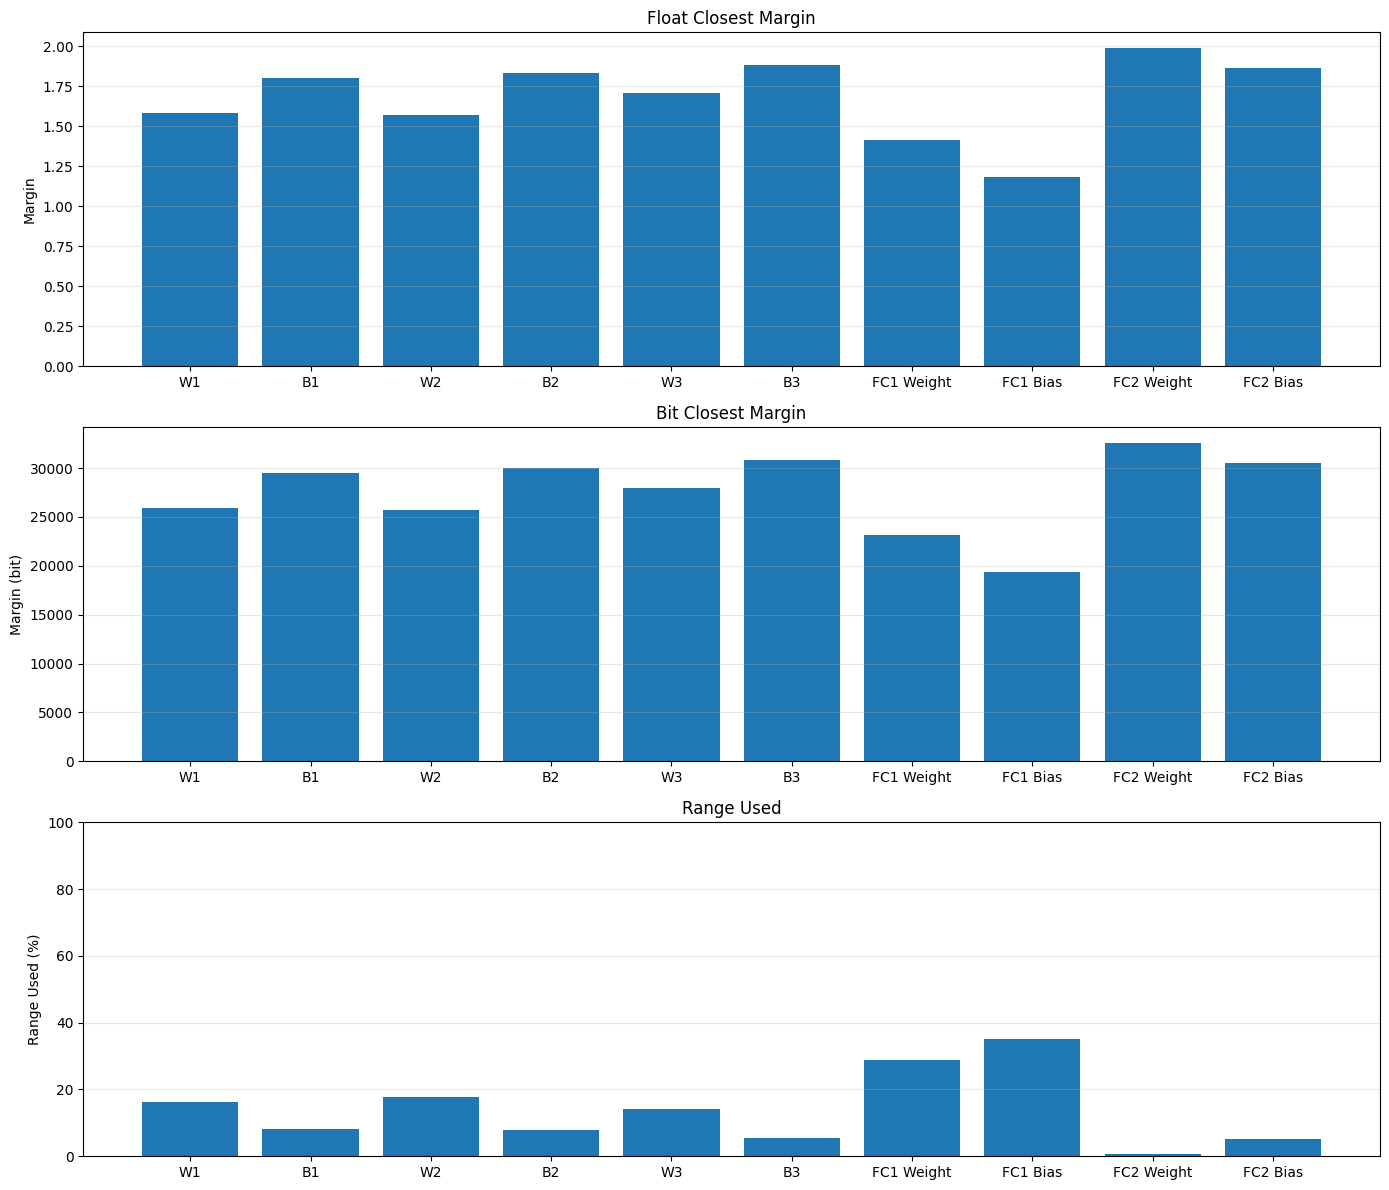

In [30]:
x = np.arange(len(labels))

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

axes[0].bar(x, float_margin)

axes[0].set_title("Float Closest Margin")
axes[0].set_ylabel("Margin")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(x, bit_margin)

axes[1].set_title("Bit Closest Margin")
axes[1].set_ylabel("Margin (bit)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(x, float_range_used)

axes[2].set_title("Range Used")
axes[2].set_ylabel("Range Used (%)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_ylim(0, 100)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()